# Lab02 - Dự đoán giá nhà bằng MLP

## 0. Xác định bài toán

**Mục tiêu nghiệp vụ:** Xây dựng mô hình học sâu (MLP) dự đoán giá bán (`SalePrice`) của một căn nhà tại Ames, Iowa dựa trên các đặc trưng vật lý và điều kiện của căn nhà. Bài toán mô phỏng nhu cầu thực tế của các đơn vị thẩm định giá bất động sản, nơi ước lượng giá nhanh và chính xác giúp hỗ trợ ra quyết định mua bán.

**Nguồn dữ liệu:** Bộ dữ liệu Ames Housing do Dean De Cock (2011) tổng hợp từ hồ sơ của Ames City Assessor's Office, gồm 2930 giao dịch nhà ở tại Ames, Iowa giai đoạn 2006–2010, với 79 thuộc tính mô tả đặc điểm căn nhà.

**Tiêu chí thành công:** Cuộc thi Kaggle "House Prices: Advanced Regression Techniques" đánh giá dựa trên RMSE giữa log(giá dự đoán) và log(giá thực tế). Vì vậy mô hình được huấn luyện để dự đoán trực tiếp `log1p(SalePrice)`, và tiêu chí thành công là Validation RMSE trên thang log càng thấp càng tốt, đồng thời Public Score trên Kaggle được dùng làm thước đo khách quan trên dữ liệu chưa quan sát.

## I. Chuẩn bị môi trường

In [1]:
import torch
import pandas as pd
import numpy as np
import sklearn

print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cpu
Pandas: 3.0.5
NumPy: 2.5.3
Scikit-learn: 1.9.1
CUDA available: False


## II. Tìm hiểu dữ liệu

Đọc tập huấn luyện và tập kiểm tra từ bộ dữ liệu House Prices.

In [2]:
train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

### 1. Kích thước dữ liệu

In [3]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


Tập huấn luyện gồm 1.460 mẫu và 81 cột, trong khi tập kiểm tra gồm 1.459 mẫu và 80 cột.
Sự chênh lệch một cột là do tập huấn luyện chứa biến mục tiêu `SalePrice`, còn tập kiểm tra không chứa biến này.

### 2. Quan sát dữ liệu ban đầu

In [4]:
train_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Dữ liệu gồm cả biến số (numerical) và biến phân loại (categorical). Ngoài ra, một số thuộc tính xuất hiện giá trị `NaN`, vì vậy cần tiếp tục khảo sát kiểu dữ liệu và giá trị thiếu trước khi xây dựng mô hình.

### 3. Xác định biến mục tiêu

Bài toán yêu cầu dự đoán giá bán của căn nhà. Biến mục tiêu là `SalePrice`, chỉ xuất hiện trong tập huấn luyện và không có trong tập kiểm tra.

In [5]:
print("SalePrice có trong train:", "SalePrice" in train_df.columns)
print("SalePrice có trong test:", "SalePrice" in test_df.columns)

train_df["SalePrice"].head()

SalePrice có trong train: True
SalePrice có trong test: False


0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

### 4. Kiểm tra các thuộc tính và kiểu dữ liệu

Kiểm tra tên cột và kiểu dữ liệu nhằm xác định các thuộc tính dạng số và dạng phân loại trong tập dữ liệu.

In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### 5. Phân loại các thuộc tính theo kiểu dữ liệu

Tập dữ liệu bao gồm cả thuộc tính dạng số và thuộc tính dạng phân loại. Việc xác định hai nhóm này là cần thiết vì chúng sẽ được tiền xử lý theo các phương pháp khác nhau trước khi đưa vào mô hình MLP.

In [7]:
numerical_cols = train_df.select_dtypes(include=["number"]).columns
categorical_cols = train_df.select_dtypes(exclude=["number"]).columns

print("Số thuộc tính dạng số:", len(numerical_cols))
print("Số thuộc tính dạng phân loại:", len(categorical_cols))

Số thuộc tính dạng số: 38
Số thuộc tính dạng phân loại: 43


Kết quả cho thấy dữ liệu chứa cả thuộc tính dạng số và dạng phân loại. Các thuộc tính dạng phân loại không thể được đưa trực tiếp vào MLP và cần được mã hóa ở bước tiền xử lý dữ liệu. Một số thuộc tính được lưu dưới dạng số có thể thực chất đại diện cho các nhóm phân loại, do đó cần xem xét thêm ý nghĩa của từng thuộc tính.

### 6. Kiểm tra giá trị thiếu

Kiểm tra số lượng và tỷ lệ giá trị thiếu của từng thuộc tính để xác định các biến cần được xử lý trong bước tiền xử lý dữ liệu.

In [8]:
missing_values = train_df.isnull().sum()
missing_percent = (missing_values / len(train_df)) * 100

missing_df = pd.DataFrame({
    "Số giá trị thiếu": missing_values,
    "Tỷ lệ thiếu (%)": missing_percent
})

missing_df = missing_df[missing_df["Số giá trị thiếu"] > 0]
missing_df = missing_df.sort_values("Tỷ lệ thiếu (%)", ascending=False)

missing_df

,Số giá trị thiếu,Tỷ lệ thiếu (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


Một số thuộc tính có tỷ lệ giá trị thiếu rất cao, tiêu biểu như `PoolQC`, `MiscFeature`, `Alley` và `Fence`. Tuy nhiên, giá trị thiếu không nhất thiết đều biểu thị dữ liệu bị mất. Với một số thuộc tính, giá trị thiếu có thể mang ý nghĩa căn nhà không có đặc điểm tương ứng. Vì vậy, cần xem xét ý nghĩa của từng thuộc tính trước khi lựa chọn phương pháp xử lý.

### 7. Thống kê mô tả các thuộc tính dạng số

Thực hiện thống kê mô tả để quan sát phân phối cơ bản của các thuộc tính dạng số, bao gồm số lượng, giá trị trung bình, độ lệch chuẩn, giá trị nhỏ nhất, lớn nhất và các phân vị.

In [9]:
train_df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### 8. Phân tích phân phối của biến mục tiêu `SalePrice`

Quan sát phân phối của giá bán nhà nhằm xác định đặc điểm của biến mục tiêu trước khi xây dựng mô hình dự đoán.

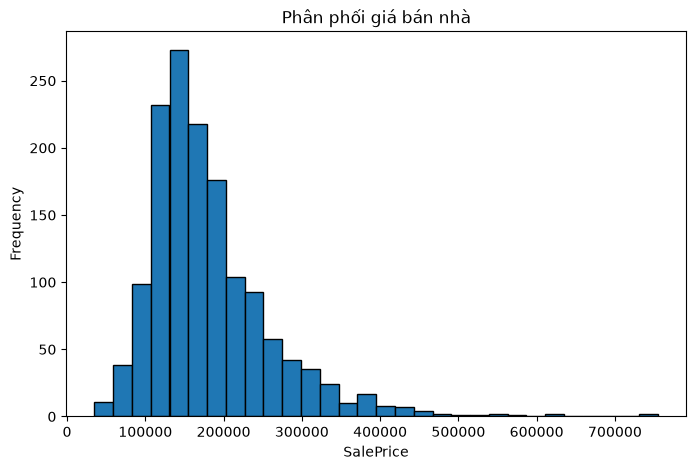

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(train_df["SalePrice"], bins=30, edgecolor="black")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")
plt.title("Phân phối giá bán nhà")
plt.savefig("../images/saleprice_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Phân phối của `SalePrice` có xu hướng lệch phải. Phần lớn các căn nhà tập trung ở vùng giá thấp và trung bình, trong khi một số ít căn nhà có giá bán rất cao tạo thành phần đuôi dài bên phải. Vì vậy, cần xem xét phép biến đổi logarit đối với biến mục tiêu trước khi huấn luyện mô hình.

### 9. Phân phối biến mục tiêu sau biến đổi logarit

Do `SalePrice` có phân phối lệch phải, thực hiện biến đổi logarit để quan sát sự thay đổi trong phân phối của biến mục tiêu.

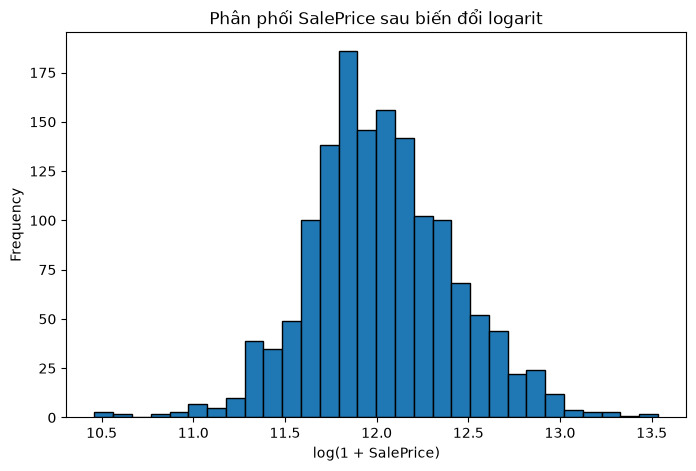

In [11]:
log_sale_price = np.log1p(train_df["SalePrice"])

plt.figure(figsize=(8, 5))
plt.hist(log_sale_price, bins=30, edgecolor="black")
plt.xlabel("log(1 + SalePrice)")
plt.ylabel("Frequency")
plt.title("Phân phối SalePrice sau biến đổi logarit")
plt.savefig("../images/saleprice_log_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Sau phép biến đổi logarit, phân phối của `SalePrice` trở nên cân đối hơn và mức độ lệch phải giảm đáng kể. Điều này cho thấy biến đổi logarit phù hợp để giảm ảnh hưởng của các giá trị giá nhà rất lớn. Do đó, `log1p(SalePrice)` sẽ được xem xét sử dụng làm biến mục tiêu khi huấn luyện mô hình MLP.

### 10. Phân tích tương quan giữa các thuộc tính dạng số và `SalePrice`

Tính hệ số tương quan giữa các thuộc tính dạng số và `SalePrice` nhằm khảo sát mức độ liên hệ tuyến tính của các thuộc tính với biến mục tiêu.

In [12]:
correlation = train_df.select_dtypes(include=["number"]).corr()["SalePrice"]
correlation = correlation.drop("SalePrice")
correlation = correlation.sort_values(ascending=False)

correlation.head(10)

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Kết quả cho thấy `OverallQual` và `GrLivArea` có tương quan dương mạnh nhất với `SalePrice`, với hệ số tương quan lần lượt khoảng 0.79 và 0.71. Ngoài ra, các thuộc tính liên quan đến gara, tầng hầm và diện tích sàn cũng có tương quan dương đáng kể với giá bán. Tuy nhiên, hệ số tương quan chỉ phản ánh mức độ liên hệ tuyến tính và không thể hiện quan hệ nhân quả.

### 11. Mối quan hệ giữa một số thuộc tính nổi bật và `SalePrice`

Quan sát trực quan mối quan hệ giữa hai thuộc tính có tương quan cao với giá bán là `OverallQual` và `GrLivArea`.

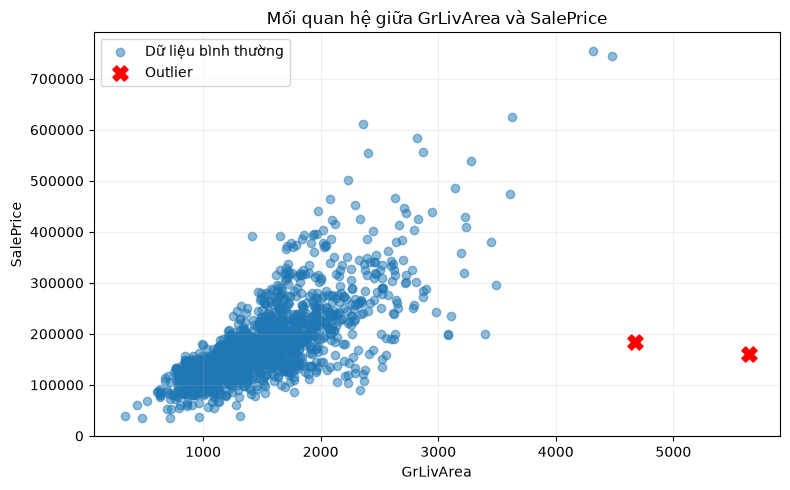

In [13]:
# Xác định 2 giá trị ngoại lai
outlier_mask = (train_df["GrLivArea"] > 4000) & (train_df["SalePrice"] < 300000)

plt.figure(figsize=(8, 5))

# Các điểm dữ liệu còn lại
plt.scatter(
    train_df.loc[~outlier_mask, "GrLivArea"],
    train_df.loc[~outlier_mask, "SalePrice"],
    alpha=0.5,
    label="Dữ liệu bình thường"
)

# Làm nổi bật 2 outlier
plt.scatter(
    train_df.loc[outlier_mask, "GrLivArea"],
    train_df.loc[outlier_mask, "SalePrice"],
    s=120,
    marker="X",
    color="red",
    label="Outlier"
)

plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.title("Mối quan hệ giữa GrLivArea và SalePrice")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "../images/grlivarea_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

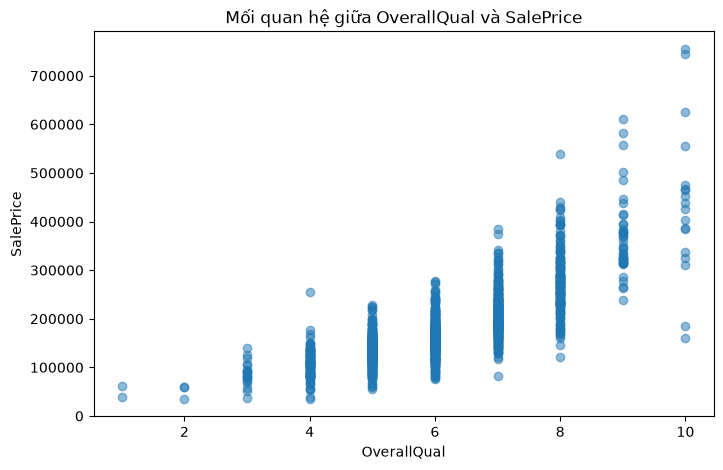

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(train_df["OverallQual"], train_df["SalePrice"], alpha=0.5)
plt.xlabel("OverallQual")
plt.ylabel("SalePrice")
plt.title("Mối quan hệ giữa OverallQual và SalePrice")
plt.show()

Hai biểu đồ cho thấy `GrLivArea` và `OverallQual` đều có mối quan hệ dương với `SalePrice`. Giá bán có xu hướng tăng khi diện tích sinh hoạt hoặc chất lượng tổng thể của căn nhà tăng. Đặc biệt, biểu đồ `GrLivArea` xuất hiện một số quan sát có diện tích rất lớn nhưng giá bán tương đối thấp, cho thấy khả năng tồn tại các giá trị ngoại lai (outlier).

### 12. Khảo sát giá trị ngoại lai

Biểu đồ giữa `GrLivArea` và `SalePrice` cho thấy một số căn nhà có diện tích sinh hoạt rất lớn nhưng giá bán thấp hơn đáng kể so với xu hướng chung. Các quan sát này được kiểm tra thêm để xác định các giá trị ngoại lai tiềm năng.

In [15]:
train_df[train_df["GrLivArea"] > 4000][
    ["Id", "GrLivArea", "OverallQual", "SalePrice"]
]

,Id,GrLivArea,OverallQual,SalePrice
523,524,4676,10,184750
691,692,4316,10,755000
1182,1183,4476,10,745000
1298,1299,5642,10,160000


Trong bốn căn nhà có `GrLivArea` lớn hơn 4000, hai quan sát có `Id` 524 và 1299 có diện tích sinh hoạt rất lớn nhưng giá bán thấp đáng kể so với xu hướng chung. Đây được xem là hai giá trị ngoại lai tiềm năng và sẽ được xử lý ở bước chuẩn bị dữ liệu.

Hai quan sát còn lại có mức giá bán cao hơn và phù hợp hơn với xu hướng giữa diện tích sinh hoạt và giá bán nên được giữ lại.

### 13. Tổng kết

Qua quá trình tìm hiểu dữ liệu, tập huấn luyện gồm 1.460 mẫu và 81 cột, trong khi tập kiểm tra gồm 1.459 mẫu và 80 cột. `SalePrice` là biến mục tiêu cần dự đoán và chỉ xuất hiện trong tập huấn luyện.

Dữ liệu bao gồm cả thuộc tính dạng số và dạng phân loại, đồng thời tồn tại giá trị thiếu ở nhiều thuộc tính. Một số giá trị thiếu có thể mang ý nghĩa căn nhà không có đặc điểm tương ứng và cần được xem xét dựa trên ý nghĩa của từng thuộc tính trước khi xử lý.

Biến mục tiêu `SalePrice` có phân phối lệch phải. Sau phép biến đổi logarit, phân phối trở nên cân đối hơn. Các thuộc tính như `OverallQual` và `GrLivArea` có tương quan dương mạnh với `SalePrice`. Ngoài ra, một số giá trị ngoại lai tiềm năng được phát hiện trong mối quan hệ giữa `GrLivArea` và `SalePrice`.

Những kết quả trên sẽ được sử dụng làm cơ sở cho bước tiền xử lý dữ liệu trước khi xây dựng mô hình MLP.

## III. Tiền xử lý dữ liệu

Dữ liệu được chuẩn bị trước khi đưa vào mô hình MLP. Các bước chính bao gồm xử lý giá trị ngoại lai, tách biến đầu vào và biến mục tiêu, điều chỉnh kiểu dữ liệu của một số thuộc tính, biến đổi biến mục tiêu, chia tập training/validation, xử lý giá trị thiếu, biến đổi các thuộc tính số có phân phối lệch, chuẩn hóa dữ liệu số và mã hóa các thuộc tính phân loại.

Toàn bộ quy trình tiền xử lý được học trên tập training và sau đó áp dụng cho tập validation và tập test nhằm hạn chế rò rỉ dữ liệu.

### 1. Xử lý giá trị ngoại lai

Dựa trên kết quả phân tích ở bước tìm hiểu dữ liệu, một số quan sát có `GrLivArea` rất lớn nhưng `SalePrice` thấp bất thường so với xu hướng chung được xác định là các giá trị ngoại lai tiềm năng. Các quan sát này được xử lý trước khi tách dữ liệu để giảm ảnh hưởng đến quá trình huấn luyện mô hình.

In [16]:
train_clean = train_df.copy()

train_clean = train_clean[
    ~((train_clean["GrLivArea"] > 4000) & (train_clean["SalePrice"] < 300000))
].copy()

print("Trước khi xử lý:", train_df.shape)
print("Sau khi xử lý:", train_clean.shape)

Trước khi xử lý: (1460, 81)
Sau khi xử lý: (1458, 81)


Hai quan sát thỏa đồng thời điều kiện `GrLivArea > 4000` và `SalePrice < 300000` được loại khỏi tập huấn luyện do có sự sai lệch rõ rệt so với xu hướng chung giữa diện tích sinh hoạt và giá bán đã quan sát ở Phần I.

Sau bước xử lý, số lượng mẫu trong tập huấn luyện giảm từ 1.460 xuống còn 1.458. Hai quan sát có `GrLivArea > 4000` còn lại vẫn được giữ lại vì mức giá bán của chúng phù hợp hơn với xu hướng chung.

### 2. Tách biến đầu vào và biến mục tiêu

Biến mục tiêu `SalePrice` được tách khỏi tập huấn luyện để tạo `y`, trong khi các thuộc tính còn lại được sử dụng làm biến đầu vào `X`.

Thuộc tính `Id` chỉ đóng vai trò định danh cho từng căn nhà và không được sử dụng làm đặc trưng huấn luyện. `Id` của tập test được lưu riêng để sử dụng khi tạo file submission cho Kaggle.

In [17]:
test_ids = test_df["Id"].copy()

X = train_clean.drop(columns=["SalePrice", "Id"])
y = train_clean["SalePrice"].copy()

X_test = test_df.drop(columns=["Id"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

X shape: (1458, 79)
y shape: (1458,)
X_test shape: (1459, 79)


Sau khi tách dữ liệu, tập huấn luyện còn 79 thuộc tính đầu vào và 1 biến mục tiêu. Tập test cũng có 79 thuộc tính đầu vào, đảm bảo cấu trúc đặc trưng giữa hai tập là nhất quán trước khi thực hiện tiền xử lý.

#### 2a. Điều chỉnh kiểu dữ liệu của `MSSubClass`

Mặc dù `MSSubClass` được lưu dưới dạng số trong dữ liệu gốc, thuộc tính này thực chất biểu diễn các mã phân loại kiểu nhà thay vì một đại lượng số liên tục. Vì vậy, `MSSubClass` được chuyển sang kiểu chuỗi để được xử lý như một thuộc tính phân loại ở các bước tiếp theo.

In [18]:
X["MSSubClass"] = X["MSSubClass"].astype(str)
X_test["MSSubClass"] = X_test["MSSubClass"].astype(str)

print("Kiểu dữ liệu MSSubClass sau khi chuyển đổi:", X["MSSubClass"].dtype)
print("Một số giá trị:", X["MSSubClass"].unique()[:5])

Kiểu dữ liệu MSSubClass sau khi chuyển đổi: str
Một số giá trị: <StringArray>
['60', '20', '70', '50', '190']
Length: 5, dtype: str


Sau khi chuyển đổi sang kiểu chuỗi, `MSSubClass` sẽ được nhóm vào các thuộc tính phân loại thay vì được xử lý như một biến số liên tục. Do đó, thuộc tính này sẽ được mã hóa bằng One-Hot Encoding thay vì được chuẩn hóa như các thuộc tính số.

### 3. Biến đổi biến mục tiêu

Do `SalePrice` có phân phối lệch phải, biến mục tiêu được biến đổi bằng hàm `log1p` nhằm giảm độ lệch của phân phối và hạn chế ảnh hưởng của các giá trị giá bán rất lớn trong quá trình huấn luyện.

In [19]:
y_log = np.log1p(y)

print("SalePrice ban đầu:")
print(y.head())

print("\nSalePrice sau log1p:")
print(y_log.head())

SalePrice ban đầu:
0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

SalePrice sau log1p:
0    12.247699
1    12.109016
2    12.317171
3    11.849405
4    12.429220
Name: SalePrice, dtype: float64


Sau phép biến đổi, biến mục tiêu được đưa về thang `log1p`. Đây sẽ là giá trị mục tiêu được sử dụng trong quá trình huấn luyện và đánh giá mô hình trên tập validation.

Khi cần diễn giải kết quả dự đoán dưới đơn vị giá bán ban đầu, phép biến đổi ngược `expm1` sẽ được sử dụng.

### 4. Chia tập huấn luyện và tập validation

Dữ liệu huấn luyện được chia thành hai phần: tập training dùng để huấn luyện mô hình và tập validation dùng để đánh giá khả năng dự đoán trên dữ liệu mà mô hình chưa được học. Tỷ lệ được sử dụng là 80% cho training và 20% cho validation.

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1166, 79)
X_val: (292, 79)
y_train: (1166,)
y_val: (292,)


Sau khi chia dữ liệu, tập training gồm 1.166 mẫu và tập validation gồm 292 mẫu. Cả hai tập đều có 79 thuộc tính đầu vào trước khi thực hiện các bước tiền xử lý.

Các bước như xử lý giá trị thiếu, biến đổi các thuộc tính số, chuẩn hóa và One-Hot Encoding sẽ được học từ tập training, sau đó áp dụng lại cho tập validation và tập test.

### 5. Xác định thuộc tính số và thuộc tính phân loại

Các thuộc tính đầu vào được chia thành hai nhóm dựa trên kiểu dữ liệu sau khi đã điều chỉnh `MSSubClass`:

- **Thuộc tính số (numerical):** được xử lý giá trị thiếu và chuẩn hóa trước khi đưa vào mô hình.
- **Thuộc tính phân loại (categorical):** được xử lý giá trị thiếu và chuyển đổi sang dạng số bằng One-Hot Encoding.

Việc tách hai nhóm thuộc tính cho phép xây dựng quy trình tiền xử lý phù hợp với đặc điểm của từng loại dữ liệu.

In [22]:
numerical_features = X_train.select_dtypes(include=["number"]).columns
categorical_features = X_train.select_dtypes(exclude=["number"]).columns

print("Số thuộc tính dạng số:", len(numerical_features))
print("Số thuộc tính dạng phân loại:", len(categorical_features))
print("Tổng số thuộc tính:", len(numerical_features) + len(categorical_features))

Số thuộc tính dạng số: 35
Số thuộc tính dạng phân loại: 44
Tổng số thuộc tính: 79


Sau khi phân loại, dữ liệu gồm 35 thuộc tính số và 44 thuộc tính phân loại, tổng cộng 79 thuộc tính đầu vào. `MSSubClass` được xếp vào nhóm thuộc tính phân loại do đã được chuyển sang kiểu chuỗi ở bước trước.

Hai nhóm thuộc tính này sẽ được áp dụng các quy trình tiền xử lý riêng trước khi được kết hợp lại bằng `ColumnTransformer`.

### 6. Xây dựng quy trình tiền xử lý

Các thuộc tính dạng số được chia thành hai nhóm dựa trên mức độ lệch của phân phối. Một số thuộc tính số không âm có độ lệch lớn được biến đổi bằng `log1p` trước khi chuẩn hóa, trong khi các thuộc tính số còn lại được chuẩn hóa trực tiếp. Giá trị thiếu của các thuộc tính số được thay thế bằng trung vị.

Đối với các thuộc tính dạng phân loại, giá trị thiếu được thay thế bằng nhãn `Missing` và One-Hot Encoding được sử dụng để chuyển dữ liệu sang dạng số.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#### 6a. Xử lý các thuộc tính số có phân phối lệch

Mức độ bất đối xứng của các thuộc tính số được khảo sát thông qua hệ số skewness. Những thuộc tính có trị tuyệt đối của hệ số skewness lớn cho thấy phân phối có mức độ bất đối xứng đáng kể, có thể ảnh hưởng đến quá trình học của mô hình.

Trong quy trình này, các thuộc tính số có giá trị không âm và `|skewness| > 0.75` được xem xét để áp dụng phép biến đổi `log1p`. Phép biến đổi này giúp giảm độ lệch của phân phối trước khi dữ liệu được chuẩn hóa.

In [24]:
numeric_skewness = X_train[numerical_features].skew().sort_values(ascending=False)

numeric_skewness.head(15)

MiscVal          22.422973
PoolArea         15.693889
LotArea          12.297772
LowQualFinSF      9.962023
3SsnPorch         9.725868
KitchenAbvGr      4.336292
ScreenPorch       4.088948
BsmtFinSF2        4.038406
BsmtHalfBath      3.856293
EnclosedPorch     3.150190
MasVnrArea        2.441177
OpenPorchSF       2.406457
LotFrontage       1.758830
WoodDeckSF        1.550852
GrLivArea         1.077392
dtype: float64

Các thuộc tính có `|skewness| > 0.75` được xác định là những thuộc tính có phân phối lệch đáng kể. Tuy nhiên, không phải tất cả các thuộc tính thỏa điều kiện này đều được biến đổi ngay; đặc điểm và ý nghĩa của từng thuộc tính cũng được xem xét trước khi áp dụng `log1p`.

In [25]:
non_negative_features = [
    col for col in numerical_features
    if X_train[col].dropna().min() >= 0
]

skewed_features = [
    col for col in non_negative_features
    if abs(X_train[col].dropna().skew()) > 0.75
]

print("Số thuộc tính số:", len(numerical_features))
print("Số thuộc tính được chọn để log1p:", len(skewed_features))

print("\nCác thuộc tính được chọn:")
print(skewed_features)

Số thuộc tính số: 35
Số thuộc tính được chọn để log1p: 19

Các thuộc tính được chọn:
['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


In [26]:
for i, feature in enumerate(skewed_features, start=1):
    print(
        f"{i:2}. {feature:<15} "
        f"skew = {X_train[feature].dropna().skew():.4f}"
    )

 1. LotFrontage     skew = 1.7588
 2. LotArea         skew = 12.2978
 3. MasVnrArea      skew = 2.4412
 4. BsmtFinSF1      skew = 0.7577
 5. BsmtFinSF2      skew = 4.0384
 6. BsmtUnfSF       skew = 0.9601
 7. 1stFlrSF        skew = 0.8870
 8. 2ndFlrSF        skew = 0.8381
 9. LowQualFinSF    skew = 9.9620
10. GrLivArea       skew = 1.0774
11. BsmtHalfBath    skew = 3.8563
12. KitchenAbvGr    skew = 4.3363
13. WoodDeckSF      skew = 1.5509
14. OpenPorchSF     skew = 2.4065
15. EnclosedPorch   skew = 3.1502
16. 3SsnPorch       skew = 9.7259
17. ScreenPorch     skew = 4.0889
18. PoolArea        skew = 15.6939
19. MiscVal         skew = 22.4230


In [27]:
excluded_from_log = [
    "BsmtHalfBath",
    "KitchenAbvGr"
]

skewed_features = [
    feature for feature in skewed_features
    if feature not in excluded_from_log
]

print("Số thuộc tính được log1p:", len(skewed_features))
print("\nCác thuộc tính được log1p:")

for feature in skewed_features:
    print("-", feature)

Số thuộc tính được log1p: 17

Các thuộc tính được log1p:
- LotFrontage
- LotArea
- MasVnrArea
- BsmtFinSF1
- BsmtFinSF2
- BsmtUnfSF
- 1stFlrSF
- 2ndFlrSF
- LowQualFinSF
- GrLivArea
- WoodDeckSF
- OpenPorchSF
- EnclosedPorch
- 3SsnPorch
- ScreenPorch
- PoolArea
- MiscVal


Sau khi xem xét, `BsmtHalfBath` và `KitchenAbvGr` được giữ nguyên do đây là các biến đếm rời rạc với số lượng giá trị nhỏ. `MSSubClass` đã được xử lý như một thuộc tính phân loại ở bước trước nên không tham gia quá trình lựa chọn các thuộc tính số có phân phối lệch.

Cuối cùng, có 17 thuộc tính số được lựa chọn để áp dụng phép biến đổi `log1p`.

#### 6b. Tiền xử lý thuộc tính số

Các thuộc tính số được chia thành hai nhóm và áp dụng quy trình tiền xử lý riêng:

- **Nhóm có phân phối lệch:** giá trị thiếu được thay thế bằng trung vị, sau đó áp dụng phép biến đổi `log1p` và chuẩn hóa bằng `StandardScaler`.
- **Nhóm còn lại:** giá trị thiếu được thay thế bằng trung vị và chuẩn hóa trực tiếp bằng `StandardScaler`, không áp dụng `log1p`.

Việc chuẩn hóa giúp đưa các thuộc tính số về thang đo tương đồng trước khi được đưa vào mô hình MLP.

In [28]:
from sklearn.preprocessing import FunctionTransformer

other_numerical_features = [
    feature for feature in numerical_features
    if feature not in skewed_features
]

skewed_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

other_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Số thuộc tính log1p:", len(skewed_features))
print("Số thuộc tính số còn lại:", len(other_numerical_features))
print("Tổng:", len(skewed_features) + len(other_numerical_features))

Số thuộc tính log1p: 17
Số thuộc tính số còn lại: 18
Tổng: 35


#### 6c. Tiền xử lý thuộc tính phân loại

Đối với các thuộc tính phân loại, giá trị thiếu được thay thế bằng nhãn `"Missing"` nhằm giữ lại thông tin về trạng thái thiếu dữ liệu. Sau đó, One-Hot Encoding được sử dụng để chuyển các giá trị phân loại thành các đặc trưng số mà mô hình MLP có thể xử lý.

Tham số `handle_unknown="ignore"` được sử dụng để tránh lỗi khi tập validation hoặc tập test xuất hiện một giá trị phân loại chưa có trong tập training.

In [29]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

#### 6d. Kết hợp các quy trình tiền xử lý

`ColumnTransformer` được sử dụng để kết hợp các quy trình tiền xử lý cho từng nhóm thuộc tính. Nhóm thuộc tính số có phân phối lệch được xử lý giá trị thiếu, biến đổi bằng `log1p` và chuẩn hóa; nhóm thuộc tính số còn lại được xử lý giá trị thiếu và chuẩn hóa trực tiếp; các thuộc tính phân loại được xử lý giá trị thiếu và mã hóa bằng One-Hot Encoding.

Việc kết hợp các bước trong một `ColumnTransformer` giúp đảm bảo cùng một quy trình tiền xử lý được áp dụng nhất quán cho tập training, validation và test.

In [30]:
preprocessor = ColumnTransformer([
    ("skewed_num", skewed_numerical_pipeline, skewed_features),
    ("other_num", other_numerical_pipeline, other_numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

### 7. Áp dụng quy trình tiền xử lý

Quy trình tiền xử lý được `fit` trên tập training để học các tham số cần thiết như giá trị trung vị dùng để xử lý dữ liệu thiếu, tham số chuẩn hóa và các nhóm giá trị của One-Hot Encoding.

Sau đó, cùng một quy trình đã học được sử dụng để biến đổi tập validation và tập test mà không thực hiện `fit` lại. Cách thực hiện này giúp hạn chế rò rỉ thông tin từ tập validation và tập test vào quá trình huấn luyện.

In [31]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("X_train sau tiền xử lý:", X_train_processed.shape)
print("X_val sau tiền xử lý:", X_val_processed.shape)
print("X_test sau tiền xử lý:", X_test_processed.shape)

X_train sau tiền xử lý: (1166, 313)
X_val sau tiền xử lý: (292, 313)
X_test sau tiền xử lý: (1459, 313)


Sau quá trình tiền xử lý, số lượng đặc trưng tăng từ 79 lên 313, chủ yếu do các thuộc tính phân loại được chuyển đổi thành nhiều đặc trưng nhị phân thông qua One-Hot Encoding.

Số lượng mẫu của các tập training, validation và test không thay đổi, đồng thời cả ba tập đều có cùng 313 đặc trưng đầu vào. Điều này đảm bảo dữ liệu có cấu trúc nhất quán trước khi được đưa vào mô hình.

### 8. Kiểm tra dữ liệu sau tiền xử lý

Trước khi chuyển dữ liệu sang PyTorch Tensor, các tập dữ liệu sau tiền xử lý được kiểm tra để đảm bảo không còn giá trị thiếu hoặc giá trị vô hạn. Đồng thời, kiểu dữ liệu và giá trị tuyệt đối lớn nhất của các đặc trưng cũng được kiểm tra nhằm phát hiện các vấn đề bất thường sau quá trình biến đổi.

In [32]:
print("Kiểu dữ liệu:", X_train_processed.dtype)

print("\nSố NaN:")
print("X_train:", np.isnan(X_train_processed).sum())
print("X_val:", np.isnan(X_val_processed).sum())
print("X_test:", np.isnan(X_test_processed).sum())

print("\nSố giá trị vô hạn (inf):")
print("X_train:", np.isinf(X_train_processed).sum())
print("X_val:", np.isinf(X_val_processed).sum())
print("X_test:", np.isinf(X_test_processed).sum())

print("\nGiá trị tuyệt đối lớn nhất:")
print("X_train:", np.abs(X_train_processed).max())
print("X_val:", np.abs(X_val_processed).max())
print("X_test:", np.abs(X_test_processed).max())

Kiểu dữ liệu: float64

Số NaN:
X_train: 0
X_val: 0
X_test: 0

Số giá trị vô hạn (inf):
X_train: 0
X_val: 0
X_test: 0

Giá trị tuyệt đối lớn nhất:
X_train: 15.776870144279986
X_val: 15.18336004433849
X_test: 15.97009656212989


Sau tiền xử lý, cả ba tập dữ liệu đều có kiểu `float64` và không còn giá trị thiếu (`NaN`) hoặc giá trị vô hạn (`inf`). Giá trị tuyệt đối lớn nhất của các đặc trưng sau biến đổi và chuẩn hóa nằm trong khoảng 15–16.

Như vậy, dữ liệu đã được chuyển hoàn toàn sang dạng số và đủ điều kiện để chuyển sang PyTorch Tensor.

### 9. Chuyển dữ liệu sang PyTorch Tensor

Các tập dữ liệu sau tiền xử lý được chuyển sang PyTorch Tensor với kiểu dữ liệu `float32`, phù hợp với kiểu dữ liệu thường được sử dụng trong quá trình huấn luyện mạng neural.

Biến mục tiêu của tập training và validation được chuyển thành Tensor và định dạng về `(số mẫu, 1)` để phù hợp với lớp đầu ra gồm một neuron của mô hình MLP.

#### 9a. Chuyển dữ liệu đầu vào và biến mục tiêu sang Tensor

Các tập dữ liệu đầu vào sau tiền xử lý được chuyển từ NumPy array sang PyTorch Tensor với kiểu dữ liệu `float32`. Biến mục tiêu của tập training và validation được chuyển sang Tensor và định dạng lại thành dạng hai chiều `(số mẫu, 1)` để phù hợp với đầu ra của mô hình hồi quy.

In [33]:
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)

#### 9b. Kiểm tra kích thước và kiểu dữ liệu của các Tensor sau khi chuyển đổi.

In [34]:
print("X_train_tensor:", X_train_tensor.shape)
print("y_train_tensor:", y_train_tensor.shape)

print("X_val_tensor:", X_val_tensor.shape)
print("y_val_tensor:", y_val_tensor.shape)

print("X_test_tensor:", X_test_tensor.shape)

print("\nKiểu dữ liệu X:", X_train_tensor.dtype)
print("Kiểu dữ liệu y:", y_train_tensor.dtype)

X_train_tensor: torch.Size([1166, 313])
y_train_tensor: torch.Size([1166, 1])
X_val_tensor: torch.Size([292, 313])
y_val_tensor: torch.Size([292, 1])
X_test_tensor: torch.Size([1459, 313])

Kiểu dữ liệu X: torch.float32
Kiểu dữ liệu y: torch.float32


Sau khi chuyển đổi, các Tensor đầu vào và biến mục tiêu đều có kiểu `torch.float32`. Tập training có kích thước `(1166, 313)`, tập validation có kích thước `(292, 313)` và tập test có kích thước `(1459, 313)`.

Biến mục tiêu của tập training và validation có dạng `(số mẫu, 1)`, phù hợp với đầu ra một neuron của mô hình hồi quy MLP.

### 10. Tạo TensorDataset và DataLoader

PyTorch `TensorDataset` được sử dụng để ghép các Tensor đặc trưng với Tensor biến mục tiêu tương ứng. Sau đó, `DataLoader` được sử dụng để chia dữ liệu thành các mini-batch phục vụ quá trình huấn luyện và đánh giá mô hình.

#### 10a. Tạo TensorDataset

`TensorDataset` được sử dụng để ghép các thuộc tính đầu vào `X` với biến mục tiêu `y` tương ứng của từng mẫu.

In [35]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

print("Số mẫu training:", len(train_dataset))
print("Số mẫu validation:", len(val_dataset))

Số mẫu training: 1166
Số mẫu validation: 292


`train_dataset` chứa 1.166 mẫu và `val_dataset` chứa 292 mẫu, tương ứng với số lượng quan sát trong hai tập sau khi chia dữ liệu.

#### 10b. Tạo DataLoader

Tập training được chia thành các mini-batch có kích thước 32 và được xáo trộn trong quá trình huấn luyện. Việc xáo trộn giúp thay đổi thứ tự các mẫu giữa các epoch.

Đối với tập validation, dữ liệu không được xáo trộn vì tập này chỉ được sử dụng để đánh giá mô hình.

In [36]:
batch_size = 32

generator = torch.Generator()
generator.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Batch size:", batch_size)
print("Số batch training:", len(train_loader))
print("Số batch validation:", len(val_loader))

Batch size: 32
Số batch training: 37
Số batch validation: 10


In [37]:
X_batch, y_batch = next(iter(train_loader))

print("X_batch:", X_batch.shape)
print("y_batch:", y_batch.shape)
print("Kiểu dữ liệu X_batch:", X_batch.dtype)
print("Kiểu dữ liệu y_batch:", y_batch.dtype)

X_batch: torch.Size([32, 313])
y_batch: torch.Size([32, 1])
Kiểu dữ liệu X_batch: torch.float32
Kiểu dữ liệu y_batch: torch.float32


Sau khi tạo `DataLoader`, tập training được chia thành các mini-batch có kích thước tối đa 32 và được xáo trộn trong quá trình huấn luyện. Tập validation cũng được chia theo batch nhưng giữ nguyên thứ tự vì chỉ được sử dụng để đánh giá mô hình.

Kết quả kiểm tra một batch training cho thấy dữ liệu đầu vào có kích thước `(32, 313)` và biến mục tiêu có kích thước `(32, 1)`, phù hợp với cấu trúc đầu vào và đầu ra dự kiến của mô hình MLP.

## IV. Xây dựng và huấn luyện mô hình MLP

Sau khi hoàn tất quá trình tiền xử lý, dữ liệu được sử dụng để xây dựng mô hình Multilayer Perceptron (MLP) bằng PyTorch nhằm dự đoán giá nhà.

Mô hình nhận các đặc trưng đầu vào sau tiền xử lý và dự đoán một giá trị duy nhất tương ứng với `log1p(SalePrice)`. Trước tiên, một mô hình MLP baseline được xây dựng và huấn luyện để làm cơ sở cho việc đánh giá và so sánh với các phiên bản cải tiến ở phần sau.

### 1. Thiết lập khả năng tái lập

Các giá trị seed được thiết lập trước khi khởi tạo và huấn luyện mô hình nhằm giúp kết quả có thể tái lập giữa các lần chạy notebook.

`DataLoader` của tập training cũng được khởi tạo lại với một generator có seed cố định để thứ tự xáo trộn các mini-batch không phụ thuộc vào cell kiểm tra batch đã thực hiện ở phần trước.

In [38]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Random seed:", SEED)

Random seed: 42


### 2. Xác định kích thước đầu vào

Số neuron của lớp đầu vào được xác định trực tiếp từ số lượng đặc trưng sau quá trình tiền xử lý. Việc lấy kích thước trực tiếp từ dữ liệu giúp mô hình tự động thích ứng nếu số lượng đặc trưng thay đổi.

In [39]:
input_size = X_train_tensor.shape[1]

print("Số thuộc tính đầu vào:", input_size)

Số thuộc tính đầu vào: 313


Sau quá trình tiền xử lý, mỗi mẫu dữ liệu có 313 đặc trưng. Vì vậy, lớp đầu tiên của mô hình MLP sẽ nhận 313 giá trị đầu vào.

### 3. Xây dựng kiến trúc MLP baseline

Mô hình Multilayer Perceptron (MLP) được xây dựng bằng PyTorch cho bài toán hồi quy. Mô hình gồm ba lớp ẩn với số neuron lần lượt là 256, 128 và 64. Sau mỗi lớp ẩn, hàm kích hoạt ReLU được sử dụng để đưa tính phi tuyến vào mô hình.

Lớp đầu ra gồm một neuron và không sử dụng hàm kích hoạt, phù hợp với bài toán hồi quy dự đoán một giá trị liên tục trên thang `log1p(SalePrice)`.

Phiên bản baseline chưa sử dụng các kỹ thuật regularization như Dropout hoặc Weight Decay. Các kỹ thuật này sẽ được thử nghiệm ở phần cải tiến mô hình.

In [40]:
import torch.nn as nn

class HousePriceMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

### 4. Khởi tạo và kiểm tra mô hình

Mô hình MLP được khởi tạo với số lượng đặc trưng đầu vào đã xác định. Sau đó, một batch dữ liệu được đưa qua mô hình để kiểm tra kích thước đầu ra và đảm bảo kiến trúc hoạt động đúng trước khi bắt đầu huấn luyện.

In [41]:
model = HousePriceMLP(input_size)

print(model)

HousePriceMLP(
  (network): Sequential(
    (0): Linear(in_features=313, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [42]:
model.eval()

with torch.no_grad():
    sample_output = model(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", sample_output.shape)

Input shape: torch.Size([32, 313])
Output shape: torch.Size([32, 1])


Mô hình nhận một batch gồm 32 mẫu với 313 đặc trưng cho mỗi mẫu và trả về 32 giá trị dự đoán, mỗi mẫu tương ứng với một giá trị đầu ra. Kích thước đầu ra `(32, 1)` phù hợp với kích thước của biến mục tiêu.

### 5. Xác định hàm mất mát và Optimizer

Đối với mô hình MLP baseline, Mean Squared Error (MSE) được sử dụng làm hàm mất mát để đo sai số giữa giá trị dự đoán và giá trị thực tế trên thang `log1p(SalePrice)`.

Thuật toán Adam được sử dụng để cập nhật các tham số của mô hình trong quá trình huấn luyện với learning rate bằng `0.001`. Phiên bản baseline chưa sử dụng Weight Decay để làm cơ sở so sánh với các mô hình cải tiến ở phần sau.

In [43]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


MSE được sử dụng làm hàm mất mát trong quá trình tối ưu, trong khi Adam với learning rate `0.001` được sử dụng để cập nhật trọng số của mô hình. Các thiết lập này được giữ cố định cho mô hình baseline.

### 6. Huấn luyện mô hình baseline

Mô hình baseline được huấn luyện tối đa 200 epoch. Early Stopping với `patience = 20` được sử dụng để dừng quá trình huấn luyện nếu Validation RMSE không cải thiện trong 20 epoch liên tiếp.

Trong mỗi epoch, dữ liệu training được xử lý theo từng mini-batch để thực hiện lan truyền thuận, tính hàm mất mát, lan truyền ngược và cập nhật trọng số. RMSE được tính trên cả tập training và tập validation.

Trạng thái mô hình có Validation RMSE thấp nhất được lưu lại. Việc sử dụng cùng số epoch tối đa và cùng điều kiện Early Stopping với các phiên bản cải tiến giúp quá trình so sánh giữa các mô hình nhất quán hơn.

In [44]:
import copy

max_epochs = 200
patience = 20

train_rmses = []
val_rmses = []

best_val_rmse = float("inf")
best_epoch = 0
best_model_state = None

epochs_without_improvement = 0

for epoch in range(max_epochs):

    # ===== Training =====
    model.train()

    train_squared_error = 0.0
    train_samples = 0

    for X_batch_train, y_batch_train in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch_train)

        loss = criterion(predictions, y_batch_train)

        loss.backward()
        optimizer.step()

        train_squared_error += torch.sum(
            (predictions.detach() - y_batch_train) ** 2
        ).item()

        train_samples += y_batch_train.size(0)

    train_rmse = np.sqrt(
        train_squared_error / train_samples
    )
    train_rmses.append(train_rmse)

    # ===== Validation =====
    model.eval()

    val_squared_error = 0.0
    val_samples = 0

    with torch.no_grad():
        for X_batch_val, y_batch_val in val_loader:

            val_predictions = model(X_batch_val)

            val_squared_error += torch.sum(
                (val_predictions - y_batch_val) ** 2
            ).item()

            val_samples += y_batch_val.size(0)

    val_rmse = np.sqrt(
        val_squared_error / val_samples
    )
    val_rmses.append(val_rmse)

    # ===== Best model / Early Stopping =====
    if val_rmse < best_val_rmse:

        best_val_rmse = val_rmse
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) == 1 or (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{max_epochs}] "
            f"- Train RMSE: {train_rmse:.4f} "
            f"- Val RMSE: {val_rmse:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping tại epoch {epoch + 1}")
        break

print("\nBest epoch:", best_epoch)
print(f"Best Validation RMSE: {best_val_rmse:.6f}")

Epoch [1/200] - Train RMSE: 7.5267 - Val RMSE: 2.2960
Epoch [10/200] - Train RMSE: 0.1026 - Val RMSE: 0.1410
Epoch [20/200] - Train RMSE: 0.0817 - Val RMSE: 0.1417
Epoch [30/200] - Train RMSE: 0.0720 - Val RMSE: 0.1424

Early stopping tại epoch 32

Best epoch: 12
Best Validation RMSE: 0.133736


Mô hình baseline cải thiện nhanh trong những epoch đầu và đạt Validation RMSE thấp nhất là `0.133736` tại epoch 12.

Sau epoch 12, Validation RMSE không tiếp tục cải thiện trong 20 epoch liên tiếp. Theo điều kiện Early Stopping với `patience = 20`, quá trình huấn luyện được dừng tại epoch 32.

Trạng thái mô hình tại epoch 12 được lưu lại và lựa chọn làm mô hình baseline tốt nhất để sử dụng cho bước đánh giá tiếp theo.

### 7. Khôi phục mô hình tốt nhất

Trong quá trình huấn luyện, trạng thái của mô hình có Validation RMSE thấp nhất đã được lưu lại. Sau khi quá trình huấn luyện kết thúc (Early Stopping dừng tại epoch 32), trạng thái này được khôi phục để đảm bảo các bước đánh giá và dự đoán tiếp theo sử dụng phiên bản tốt nhất của mô hình baseline.

In [45]:
model.load_state_dict(best_model_state)
model.eval()

print("Đã khôi phục mô hình tại epoch:", best_epoch)
print(f"Best Validation RMSE: {best_val_rmse:.6f}")

Đã khôi phục mô hình tại epoch: 12
Best Validation RMSE: 0.133736


Mô hình tại epoch 12 được khôi phục do đạt Validation RMSE thấp nhất trong quá trình huấn luyện. Mô hình này sẽ được sử dụng cho bước đánh giá trên tập validation.

## V. Đánh giá mô hình

Sau khi khôi phục trạng thái tốt nhất của mô hình MLP baseline, mô hình được đánh giá trên tập validation nhằm đo lường khả năng dự đoán trên dữ liệu không được sử dụng để cập nhật trọng số trong quá trình huấn luyện.

Việc đánh giá được thực hiện trên thang `log1p(SalePrice)` bằng RMSE. Sau đó, các giá trị dự đoán được chuyển ngược về thang giá bán ban đầu để phân tích sai số và trực quan hóa kết quả.

### 1. Dự đoán trên tập validation

Mô hình được chuyển sang chế độ đánh giá bằng `model.eval()`. Quá trình dự đoán được thực hiện trong `torch.no_grad()` vì không cần tính gradient hoặc cập nhật trọng số.

In [46]:
model.eval()

with torch.no_grad():
    val_predictions = model(X_val_tensor)

print("Kích thước dự đoán:", val_predictions.shape)
print("Kích thước giá trị thực:", y_val_tensor.shape)

Kích thước dự đoán: torch.Size([292, 1])
Kích thước giá trị thực: torch.Size([292, 1])


Mô hình tạo ra 292 giá trị dự đoán tương ứng với 292 mẫu trong tập validation. Kích thước của giá trị dự đoán và giá trị thực đều là `(292, 1)`, cho thấy đầu ra của mô hình phù hợp với biến mục tiêu.

### 2. Tính RMSE trên tập validation

Hiệu quả của mô hình được đánh giá bằng Root Mean Squared Error (RMSE) giữa giá trị dự đoán và giá trị thực trên thang `log1p(SalePrice)`. RMSE càng thấp cho thấy sai số dự đoán của mô hình càng nhỏ.

In [47]:
val_mse = torch.mean(
    (val_predictions - y_val_tensor) ** 2
).item()

val_rmse = np.sqrt(val_mse)

print(f"Validation MSE: {val_mse:.6f}")
print(f"Validation RMSE: {val_rmse:.6f}")

Validation MSE: 0.017885
Validation RMSE: 0.133736


Mô hình baseline đạt Validation RMSE bằng `0.133736` trên thang `log1p(SalePrice)`. Kết quả này trùng với Validation RMSE thấp nhất được ghi nhận trong quá trình huấn luyện tại epoch 12, xác nhận rằng trạng thái mô hình tốt nhất đã được khôi phục chính xác.

### 3. Chuyển kết quả về thang giá bán ban đầu

Do mô hình được huấn luyện để dự đoán `log1p(SalePrice)`, các giá trị dự đoán và giá trị thực được chuyển ngược về thang giá bán ban đầu bằng hàm `expm1`. Việc chuyển đổi này giúp kết quả dễ diễn giải hơn theo đơn vị giá bán của bộ dữ liệu.

In [48]:
val_pred_log = val_predictions.squeeze().cpu().numpy()
val_true_log = y_val_tensor.squeeze().cpu().numpy()

val_pred_price = np.expm1(val_pred_log)
val_true_price = np.expm1(val_true_log)

print("5 giá trị thực đầu tiên:")
print(val_true_price[:5])

print("\n5 giá trị dự đoán đầu tiên:")
print(val_pred_price[:5])

5 giá trị thực đầu tiên:
[189999.92  100000.016 114999.945 158999.95  315499.88 ]

5 giá trị dự đoán đầu tiên:
[235886.42   97656.67  105216.664 172457.83  344971.1  ]


Các giá trị dự đoán đã được chuyển ngược từ thang `log1p` về thang giá bán ban đầu bằng `expm1`. Sai lệch rất nhỏ giữa một số giá trị thực sau khi chuyển đổi và số nguyên ban đầu xuất phát từ độ chính xác số thực của dữ liệu `float32` và không ảnh hưởng đáng kể đến quá trình đánh giá.

### 4. Phân tích sai số dự đoán

Để đánh giá mô hình trên thang giá bán ban đầu, một bảng kết quả được xây dựng gồm giá trị thực tế, giá trị dự đoán, sai số tuyệt đối và sai số phần trăm của từng mẫu trong tập validation.

Sai số tuyệt đối cho biết mức chênh lệch giữa giá dự đoán và giá thực tế, trong khi sai số phần trăm giúp đánh giá mức độ sai lệch tương đối so với giá bán thực tế.

In [49]:
validation_results = pd.DataFrame({
    "ActualPrice": val_true_price,
    "PredictedPrice": val_pred_price
})

validation_results["AbsoluteError"] = np.abs(
    validation_results["PredictedPrice"]
    - validation_results["ActualPrice"]
)

validation_results["PercentageError"] = (
    validation_results["AbsoluteError"]
    / validation_results["ActualPrice"]
    * 100
)

validation_results.head(10)

,ActualPrice,PredictedPrice,AbsoluteError,PercentageError
0,189999.921875,235886.421875,45886.500000,24.150799
1,100000.015625,97656.671875,2343.343750,2.343343
2,114999.945312,105216.664062,9783.281250,8.507205
3,158999.953125,172457.828125,13457.875000,8.464075
4,315499.875000,344971.093750,29471.218750,9.341119
5,137500.015625,158250.671875,20750.656250,15.091385
6,311499.906250,231600.765625,79899.140625,25.649813
7,310000.062500,319932.375000,9932.312500,3.203971
8,281000.125000,268856.531250,12143.593750,4.321562
9,135500.000000,149938.171875,14438.171875,10.655478


In [50]:
print(
    f"Mean Absolute Error: "
    f"{validation_results['AbsoluteError'].mean():,.2f}"
)

print(
    f"Median Absolute Error: "
    f"{validation_results['AbsoluteError'].median():,.2f}"
)

print(
    f"Maximum Absolute Error: "
    f"{validation_results['AbsoluteError'].max():,.2f}"
)

print(
    f"\nMean Percentage Error: "
    f"{validation_results['PercentageError'].mean():.2f}%"
)

print(
    f"Median Percentage Error: "
    f"{validation_results['PercentageError'].median():.2f}%"
)

print(
    f"Maximum Percentage Error: "
    f"{validation_results['PercentageError'].max():.2f}%"
)

Mean Absolute Error: 15,669.37
Median Absolute Error: 11,578.32
Maximum Absolute Error: 114,424.28

Mean Percentage Error: 9.51%
Median Percentage Error: 6.88%
Maximum Percentage Error: 100.41%


Trên thang giá bán ban đầu, mô hình có sai số tuyệt đối trung bình khoảng `15,669.37` và sai số tuyệt đối trung vị khoảng `11,578.32`. Sai số phần trăm tuyệt đối trung bình là `9.51%`, trong khi trung vị là `6.88%`.

Sai số tuyệt đối lớn nhất trên tập validation là `114,424.28`, còn sai số phần trăm lớn nhất đạt `100.41%`. Việc sai số phần trăm trung bình cao hơn trung vị cho thấy một số mẫu có sai số tương đối lớn đã làm tăng giá trị trung bình.

Mặc dù Validation RMSE trên thang `log1p(SalePrice)` tương đối thấp, kết quả trên thang giá gốc cho thấy mô hình vẫn tồn tại một số trường hợp dự đoán sai lệch đáng kể. Vì vậy, các mẫu có sai số lớn cần được xem xét riêng để hiểu rõ hơn hạn chế của mô hình.

### 5. Phân tích các trường hợp có sai số lớn

Các mẫu có sai số phần trăm lớn nhất được kiểm tra nhằm xác định những trường hợp mà mô hình gặp khó khăn trong việc dự đoán chính xác giá bán.

In [51]:
validation_results["Id"] = train_clean.loc[
    X_val.index, "Id"
].to_numpy()

worst_predictions = (
    validation_results
    .sort_values("PercentageError", ascending=False)
    .head(10)
)

worst_predictions[
    [
        "Id",
        "ActualPrice",
        "PredictedPrice",
        "AbsoluteError",
        "PercentageError"
    ]
]

,Id,ActualPrice,PredictedPrice,AbsoluteError,PercentageError
197,31,39999.996094,80164.093750,40164.097656,100.410255
161,810,106000.039062,179633.328125,73633.289062,69.465340
227,1433,64500.011719,108412.000000,43911.988281,68.080589
59,534,39300.000000,64638.562500,25338.562500,64.474716
134,917,35311.003906,56631.582031,21320.578125,60.379417
250,748,265979.062500,151554.781250,114424.281250,43.020035
139,1032,196999.937500,265490.968750,68491.031250,34.767033
251,729,110000.015625,147107.796875,37107.781250,33.734341
214,272,241499.906250,161009.437500,80490.468750,33.329399
81,399,67000.007812,46159.316406,20840.691406,31.105507


Các trường hợp có sai số phần trăm lớn nhất cho thấy mô hình vẫn gặp khó khăn với một số mẫu trong tập validation.

Mẫu `Id = 31` có sai số phần trăm lớn nhất: giá bán thực tế khoảng `40,000`, trong khi mô hình dự đoán khoảng `80,164`, tương ứng sai số khoảng `100.41%`. Các mẫu `Id = 810`, `1433`, `534` và `917` cũng có sai số tương đối lớn.

Nhiều trường hợp trong nhóm này có giá bán thực tế tương đối thấp. Tuy nhiên, chỉ từ bảng sai số chưa thể kết luận mức giá thấp là nguyên nhân trực tiếp làm mô hình dự đoán kém; cần phân tích thêm các đặc trưng của từng căn nhà để xác định nguyên nhân cụ thể.

### 6. So sánh giá thực tế và giá dự đoán

Biểu đồ phân tán được sử dụng để so sánh giá bán thực tế và giá do mô hình dự đoán trên tập validation. Đường tham chiếu `y = x` biểu diễn trường hợp dự đoán hoàn toàn chính xác; các điểm càng gần đường này thì sai số dự đoán càng nhỏ.

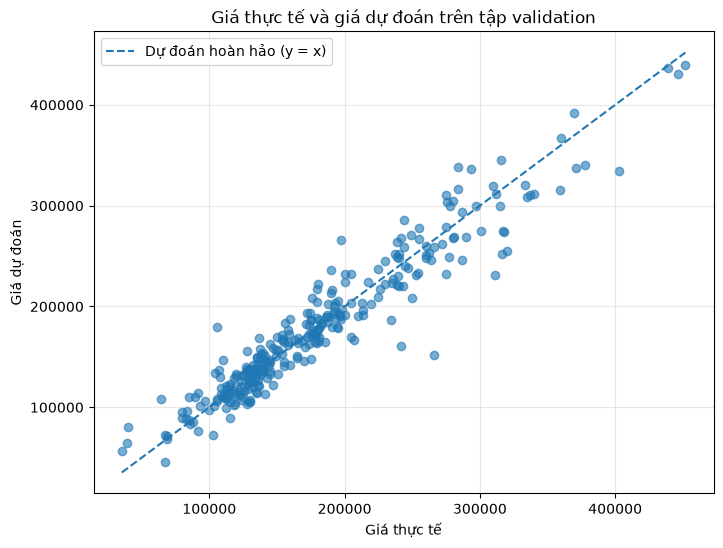

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    val_true_price,
    val_pred_price,
    alpha=0.6
)

min_price = min(val_true_price.min(), val_pred_price.min())
max_price = max(val_true_price.max(), val_pred_price.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Dự đoán hoàn hảo (y = x)"
)

plt.xlabel("Giá thực tế")
plt.ylabel("Giá dự đoán")
plt.title("Giá thực tế và giá dự đoán trên tập validation")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(
    "../images/baseline_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Phần lớn các điểm dữ liệu nằm tương đối gần đường tham chiếu `y = x`, cho thấy giá dự đoán của mô hình nhìn chung bám theo giá bán thực tế trên tập validation.

Các dự đoán tập trung khá sát đường tham chiếu ở phần lớn khoảng giá. Tuy nhiên, vẫn tồn tại một số điểm nằm xa đường `y = x`, thể hiện các trường hợp có sai số dự đoán lớn. Một số sai lệch rõ hơn cũng xuất hiện ở vùng giá trung bình và cao.

Nhìn chung, biểu đồ cho thấy mô hình đã học được mối quan hệ giữa các đặc trưng đầu vào và giá bán, nhưng vẫn còn một số trường hợp dự đoán chưa chính xác.

### 7. Phân tích quá trình huấn luyện

Đường cong RMSE của tập training và validation được trực quan hóa theo từng epoch để quan sát quá trình học của mô hình. Epoch đạt Validation RMSE thấp nhất được đánh dấu để xác định thời điểm mô hình đạt kết quả tốt nhất trên tập validation.

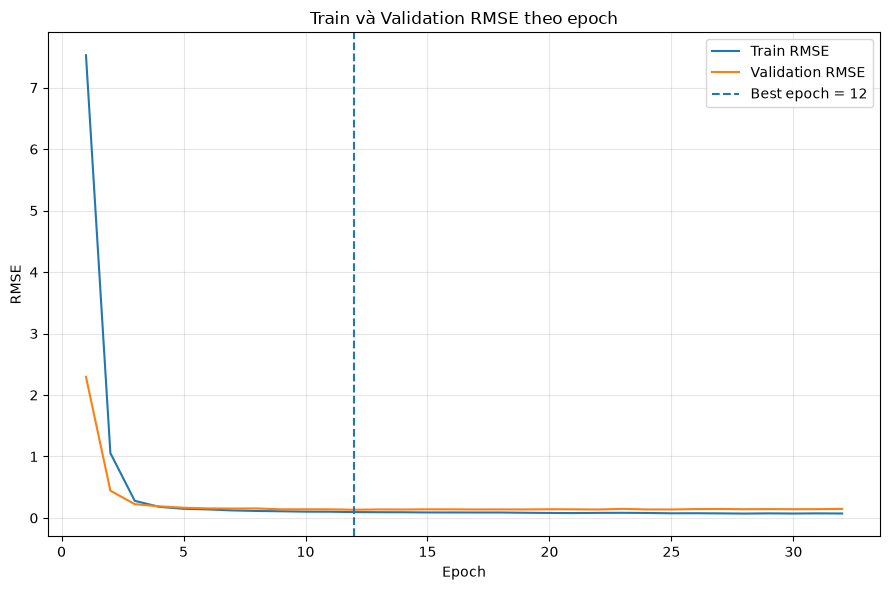

In [53]:
# Số epoch thực tế đã được huấn luyện
epochs = range(1, len(train_rmses) + 1)

plt.figure(figsize=(9, 6))

plt.plot(epochs, train_rmses, label="Train RMSE")
plt.plot(epochs, val_rmses, label="Validation RMSE")

# Đánh dấu epoch tốt nhất lấy trực tiếp từ quá trình huấn luyện
plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Train và Validation RMSE theo epoch")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../images/baseline_training_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

RMSE của cả tập training và validation giảm nhanh trong những epoch đầu tiên, cho thấy mô hình học được các quy luật chính của dữ liệu trong giai đoạn đầu huấn luyện.

Validation RMSE đạt giá trị thấp nhất là **0.133736 tại epoch 12**. Sau thời điểm này, Train RMSE tiếp tục giảm, trong khi Validation RMSE không cải thiện thêm và dao động quanh mức cao hơn. Điều này cho thấy việc tiếp tục huấn luyện không mang lại cải thiện trên tập validation và bắt đầu xuất hiện dấu hiệu overfitting.

Do Validation RMSE không cải thiện trong 20 epoch liên tiếp, Early Stopping dừng quá trình huấn luyện tại **epoch 32**. Trạng thái mô hình tại **epoch 12** được lưu lại và khôi phục làm mô hình baseline tốt nhất.

### 8. Tổng kết đánh giá mô hình

Mô hình MLP baseline đạt kết quả tốt nhất tại epoch 12 với Validation RMSE bằng `0.133736` trên thang `log1p(SalePrice)`.

Khi chuyển kết quả về thang giá bán ban đầu, mô hình có sai số tuyệt đối trung bình khoảng `15,669.37` và sai số phần trăm tuyệt đối trung bình khoảng `9.51%`. Trung vị của sai số tuyệt đối là `11,578.32`, trong khi trung vị của sai số phần trăm là `6.88%`.

Biểu đồ giữa giá thực tế và giá dự đoán cho thấy phần lớn các dự đoán bám tương đối gần giá trị thực tế, mặc dù vẫn tồn tại một số trường hợp có sai số lớn. Kết quả của mô hình baseline sẽ được sử dụng làm cơ sở để so sánh với các phiên bản MLP sử dụng regularization ở phần tiếp theo.

## VI. Cải tiến và so sánh mô hình

Sau khi xây dựng mô hình MLP baseline, một số kỹ thuật regularization được thử nghiệm nhằm đánh giá khả năng cải thiện hiệu quả dự đoán và hạn chế hiện tượng mô hình học quá sát dữ liệu training.

Hai phiên bản được xây dựng để so sánh với baseline:

- **MLP v2 – Dropout:** bổ sung các lớp Dropout giữa các lớp ẩn.
- **MLP v3 – Weight Decay:** giữ nguyên kiến trúc baseline nhưng bổ sung L2 regularization thông qua tham số `weight_decay` của Adam.

Các mô hình được đánh giá chủ yếu dựa trên Validation RMSE trên thang `log1p(SalePrice)`. Giá trị RMSE càng thấp cho thấy mô hình dự đoán tốt hơn trên tập validation.

### 1. MLP v2 – Dropout

Phiên bản thứ hai bổ sung Dropout với xác suất `0.2` sau mỗi lớp ẩn. Trong quá trình training, Dropout ngẫu nhiên vô hiệu hóa một tỷ lệ neuron nhằm giảm sự phụ thuộc quá mức vào một số neuron cụ thể.

Kiến trúc tổng thể vẫn giữ nguyên các lớp ẩn `256 → 128 → 64` để có thể so sánh với mô hình baseline.

In [54]:
class HousePriceMLPDropout(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

#### 1a. Khởi tạo v2

In [55]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

train_generator_v2 = torch.Generator()
train_generator_v2.manual_seed(SEED)

train_loader_v2 = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=train_generator_v2
)

model_v2 = HousePriceMLPDropout(input_size)

criterion_v2 = nn.MSELoss()

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=0.001
)

print(model_v2)

HousePriceMLPDropout(
  (network): Sequential(
    (0): Linear(in_features=313, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=64, out_features=1, bias=True)
  )
)


#### 1b. Huấn luyện v2 với Early Stopping

Mô hình được huấn luyện tối đa 200 epoch. Early Stopping với `patience = 20` được sử dụng để kết thúc quá trình huấn luyện nếu Validation RMSE không cải thiện trong 20 epoch liên tiếp.

Trạng thái mô hình có Validation RMSE thấp nhất vẫn được lưu lại để sử dụng cho việc đánh giá và so sánh.

In [56]:
max_epochs = 200
patience = 20

train_rmses_v2 = []
val_rmses_v2 = []

best_val_rmse_v2 = float("inf")
best_epoch_v2 = 0
best_model_state_v2 = None

epochs_without_improvement = 0

for epoch in range(max_epochs):

    # ===== Training =====
    model_v2.train()

    train_squared_error = 0.0
    train_samples = 0

    for X_batch_train, y_batch_train in train_loader_v2:

        optimizer_v2.zero_grad()

        predictions = model_v2(X_batch_train)

        loss = criterion_v2(predictions, y_batch_train)

        loss.backward()
        optimizer_v2.step()

        train_squared_error += torch.sum(
            (predictions.detach() - y_batch_train) ** 2
        ).item()

        train_samples += y_batch_train.size(0)

    train_rmse_v2 = np.sqrt(
        train_squared_error / train_samples
    )
    train_rmses_v2.append(train_rmse_v2)

    # ===== Validation =====
    model_v2.eval()

    val_squared_error = 0.0
    val_samples = 0

    with torch.no_grad():
        for X_batch_val, y_batch_val in val_loader:

            val_predictions_v2 = model_v2(X_batch_val)

            val_squared_error += torch.sum(
                (val_predictions_v2 - y_batch_val) ** 2
            ).item()

            val_samples += y_batch_val.size(0)

    val_rmse_v2 = np.sqrt(
        val_squared_error / val_samples
    )
    val_rmses_v2.append(val_rmse_v2)

    # ===== Best model / Early Stopping =====
    if val_rmse_v2 < best_val_rmse_v2:

        best_val_rmse_v2 = val_rmse_v2
        best_epoch_v2 = epoch + 1
        best_model_state_v2 = copy.deepcopy(
            model_v2.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) == 1 or (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{max_epochs}] "
            f"- Train RMSE: {train_rmse_v2:.4f} "
            f"- Val RMSE: {val_rmse_v2:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(
            f"\nEarly stopping tại epoch {epoch + 1}"
        )
        break

print("\nBest epoch:", best_epoch_v2)
print(
    f"Best Validation RMSE: "
    f"{best_val_rmse_v2:.6f}"
)

Epoch [1/200] - Train RMSE: 7.6269 - Val RMSE: 2.2361
Epoch [10/200] - Train RMSE: 1.5399 - Val RMSE: 1.0292
Epoch [20/200] - Train RMSE: 1.5512 - Val RMSE: 0.6197
Epoch [30/200] - Train RMSE: 1.5287 - Val RMSE: 0.4421
Epoch [40/200] - Train RMSE: 1.4962 - Val RMSE: 0.3304
Epoch [50/200] - Train RMSE: 1.5315 - Val RMSE: 0.3723
Epoch [60/200] - Train RMSE: 1.4124 - Val RMSE: 0.5343
Epoch [70/200] - Train RMSE: 1.4262 - Val RMSE: 0.3049
Epoch [80/200] - Train RMSE: 1.3826 - Val RMSE: 0.4955

Early stopping tại epoch 83

Best epoch: 63
Best Validation RMSE: 0.239376


MLP v2 đạt Validation RMSE thấp nhất là `0.239376` tại epoch 63 và quá trình huấn luyện dừng sớm tại epoch 83 sau 20 epoch liên tiếp không có sự cải thiện.

So với mô hình baseline có Validation RMSE `0.133736`, phiên bản sử dụng Dropout cho kết quả kém hơn đáng kể. Train RMSE của mô hình cũng duy trì ở mức tương đối cao trong quá trình huấn luyện.

Kết quả cho thấy Dropout với xác suất `0.2` chưa phù hợp với cấu hình MLP và bộ dữ liệu hiện tại. Việc loại bỏ ngẫu nhiên một phần neuron trong quá trình training có thể tạo mức regularization quá mạnh, làm giảm khả năng học của mô hình. Vì vậy, phiên bản Dropout này không được lựa chọn làm mô hình cuối cùng.

In [57]:
model_v2.load_state_dict(best_model_state_v2)
model_v2.eval()

HousePriceMLPDropout(
  (network): Sequential(
    (0): Linear(in_features=313, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=64, out_features=1, bias=True)
  )
)

### 2. MLP v3 – Weight Decay

Phiên bản thứ ba giữ nguyên kiến trúc của mô hình baseline và không sử dụng Dropout. Thay vào đó, Weight Decay được bổ sung vào optimizer Adam nhằm tạo L2 regularization đối với các tham số của mô hình.

Trong thử nghiệm này, `weight_decay = 1e-5` được sử dụng. Các thiết lập còn lại được giữ tương tự baseline để đánh giá ảnh hưởng của Weight Decay.

#### 2a. Khởi tạo MLP v3

In [58]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

train_generator_v3 = torch.Generator()
train_generator_v3.manual_seed(SEED)

train_loader_v3 = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=train_generator_v3
)

model_v3 = HousePriceMLP(input_size)

criterion_v3 = nn.MSELoss()

optimizer_v3 = torch.optim.Adam(
    model_v3.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print(model_v3)

HousePriceMLP(
  (network): Sequential(
    (0): Linear(in_features=313, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


#### 2b. Huấn luyện MLP v3

MLP v3 được huấn luyện tối đa 200 epoch với Early Stopping có `patience = 20`, tương tự phiên bản Dropout. Trạng thái có Validation RMSE thấp nhất được lưu lại trong quá trình huấn luyện.

Điểm khác biệt chính so với baseline là optimizer Adam sử dụng `weight_decay = 1e-5` nhằm bổ sung regularization vào quá trình tối ưu.

In [59]:
max_epochs = 200
patience = 20

train_rmses_v3 = []
val_rmses_v3 = []

best_val_rmse_v3 = float("inf")
best_epoch_v3 = 0
best_model_state_v3 = None

epochs_without_improvement = 0

for epoch in range(max_epochs):

    # ===== Training =====
    model_v3.train()

    train_squared_error = 0.0
    train_samples = 0

    for X_batch_train, y_batch_train in train_loader_v3:

        optimizer_v3.zero_grad()

        predictions = model_v3(X_batch_train)

        loss = criterion_v3(predictions, y_batch_train)

        loss.backward()
        optimizer_v3.step()

        train_squared_error += torch.sum(
            (predictions.detach() - y_batch_train) ** 2
        ).item()

        train_samples += y_batch_train.size(0)

    train_rmse_v3 = np.sqrt(
        train_squared_error / train_samples
    )
    train_rmses_v3.append(train_rmse_v3)

    # ===== Validation =====
    model_v3.eval()

    val_squared_error = 0.0
    val_samples = 0

    with torch.no_grad():
        for X_batch_val, y_batch_val in val_loader:

            val_predictions_v3 = model_v3(X_batch_val)

            val_squared_error += torch.sum(
                (val_predictions_v3 - y_batch_val) ** 2
            ).item()

            val_samples += y_batch_val.size(0)

    val_rmse_v3 = np.sqrt(
        val_squared_error / val_samples
    )
    val_rmses_v3.append(val_rmse_v3)

    # ===== Best model / Early Stopping =====
    if val_rmse_v3 < best_val_rmse_v3:

        best_val_rmse_v3 = val_rmse_v3
        best_epoch_v3 = epoch + 1
        best_model_state_v3 = copy.deepcopy(
            model_v3.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) == 1 or (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{max_epochs}] "
            f"- Train RMSE: {train_rmse_v3:.4f} "
            f"- Val RMSE: {val_rmse_v3:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(
            f"\nEarly stopping tại epoch {epoch + 1}"
        )
        break

print("\nBest epoch:", best_epoch_v3)
print(
    f"Best Validation RMSE: "
    f"{best_val_rmse_v3:.6f}"
)

Epoch [1/200] - Train RMSE: 7.5246 - Val RMSE: 2.3023
Epoch [10/200] - Train RMSE: 0.1026 - Val RMSE: 0.1407
Epoch [20/200] - Train RMSE: 0.0836 - Val RMSE: 0.1412
Epoch [30/200] - Train RMSE: 0.0752 - Val RMSE: 0.1405

Early stopping tại epoch 32

Best epoch: 12
Best Validation RMSE: 0.133199


In [60]:
model_v3.load_state_dict(best_model_state_v3)
model_v3.eval()

print("Đã khôi phục MLP v3 tại epoch:", best_epoch_v3)
print(f"Best Validation RMSE: {best_val_rmse_v3:.6f}")

Đã khôi phục MLP v3 tại epoch: 12
Best Validation RMSE: 0.133199


MLP v3 đạt Validation RMSE thấp nhất là `0.133199` tại epoch 12. Quá trình huấn luyện được dừng sớm tại epoch 32 sau 20 epoch liên tiếp không có sự cải thiện trên tập validation.

So với mô hình baseline có Validation RMSE `0.133736`, phiên bản sử dụng Weight Decay đạt Validation RMSE thấp hơn một khoảng nhỏ. Điều này cho thấy `weight_decay = 1e-5` mang lại sự cải thiện nhẹ trên tập validation trong thử nghiệm hiện tại.

Trạng thái mô hình tại epoch 12 đã được khôi phục và được sử dụng làm phiên bản MLP v3 tốt nhất cho bước so sánh tiếp theo.

### 3. So sánh các phiên bản MLP

Ba phiên bản MLP được so sánh dựa trên Validation RMSE thấp nhất đạt được trong quá trình huấn luyện. Tất cả các mô hình đều sử dụng cùng tập training và validation, cùng kích thước đầu vào và cùng kiến trúc các lớp ẩn, trong khi phương pháp regularization được thay đổi giữa các phiên bản.

In [61]:
model_comparison = pd.DataFrame({
    "Model": [
        "MLP v1 - Baseline",
        "MLP v2 - Dropout",
        "MLP v3 - Weight Decay"
    ],
    "Regularization": [
        "None",
        "Dropout (p=0.2)",
        "Weight Decay (1e-5)"
    ],
    "Best Epoch": [
        best_epoch,
        best_epoch_v2,
        best_epoch_v3
    ],
    "Validation RMSE": [
        best_val_rmse,
        best_val_rmse_v2,
        best_val_rmse_v3
    ]
})

model_comparison

,Model,Regularization,Best Epoch,Validation RMSE
0,MLP v1 - Baseline,None,12,0.133736
1,MLP v2 - Dropout,Dropout (p=0.2),63,0.239376
2,MLP v3 - Weight Decay,Weight Decay (1e-5),12,0.133199


Kết quả cho thấy MLP v3 sử dụng Weight Decay đạt Validation RMSE thấp nhất (`0.133199`), tiếp theo là mô hình baseline (`0.133736`). Chênh lệch giữa hai mô hình chỉ khoảng `0.000537`, cho thấy mức cải thiện của Weight Decay trên tập validation là tương đối nhỏ.

Ngược lại, MLP v2 sử dụng Dropout có Validation RMSE `0.239376`, cao hơn đáng kể so với hai mô hình còn lại. Điều này cho thấy Dropout với xác suất `0.2` chưa phù hợp với cấu hình thử nghiệm hiện tại.

Trong phạm vi ba cấu hình được thử nghiệm, MLP v3 có Validation RMSE thấp nhất và được lựa chọn để tiếp tục đánh giá trên tập test.

### 4. Trực quan hóa kết quả so sánh

Validation RMSE tốt nhất của ba phiên bản MLP được trực quan hóa để thể hiện sự khác biệt về hiệu quả dự đoán giữa các phương pháp regularization.

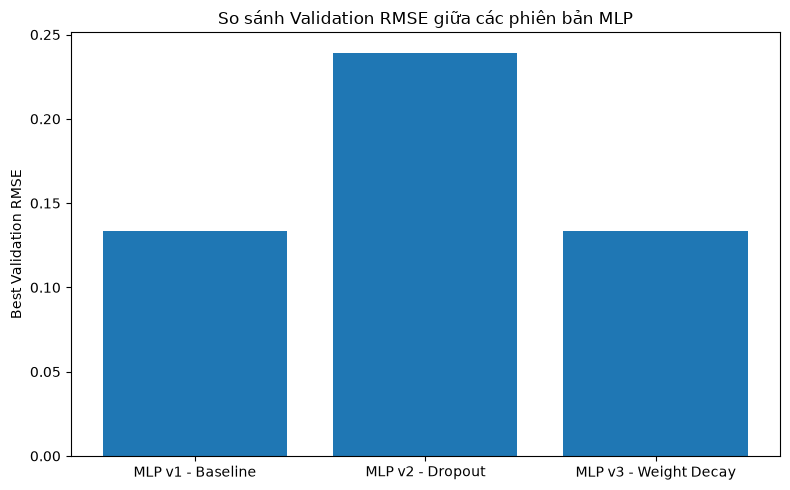

In [62]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Validation RMSE"]
)

plt.ylabel("Best Validation RMSE")
plt.title("So sánh Validation RMSE giữa các phiên bản MLP")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "../images/model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Biểu đồ cho thấy MLP baseline và MLP v3 sử dụng Weight Decay có Validation RMSE khá tương đồng, trong khi MLP v2 sử dụng Dropout có sai số cao hơn rõ rệt.

MLP v3 đạt Validation RMSE thấp nhất (`0.133199`), nhưng chỉ thấp hơn baseline (`0.133736`) một khoảng nhỏ. Vì vậy, kết quả cho thấy Weight Decay với hệ số `1e-5` mang lại cải thiện nhẹ trên tập validation trong thử nghiệm này, thay vì tạo ra sự cải thiện lớn về hiệu quả dự đoán.

### 5. Kết luận phần cải tiến mô hình

Trong ba cấu hình được thử nghiệm, MLP v3 với `weight_decay = 1e-5` đạt Validation RMSE thấp nhất là `0.133199`. Mô hình baseline đạt kết quả rất gần với RMSE `0.133736`, trong khi MLP v2 sử dụng Dropout `0.2` có RMSE cao hơn đáng kể (`0.239376`).

Kết quả cho thấy Weight Decay mang lại một mức cải thiện nhỏ so với baseline trên tập validation, trong khi cấu hình Dropout được thử nghiệm làm giảm hiệu quả dự đoán.

Do MLP v3 đạt Validation RMSE thấp nhất trong phạm vi các cấu hình đã thử nghiệm, mô hình này được lựa chọn làm mô hình cuối cùng để thực hiện dự đoán trên tập test.

## VII. Dự đoán tập test và tạo Kaggle Submission

Sau quá trình huấn luyện và so sánh ba phiên bản MLP, MLP v3 sử dụng Weight Decay với `weight_decay = 1e-5` được lựa chọn làm mô hình cuối cùng do đạt Validation RMSE thấp nhất (`0.133199`) trong các cấu hình đã thử nghiệm.

Mô hình tốt nhất của MLP v3 được sử dụng để dự đoán `SalePrice` cho tập test. Các kết quả dự đoán sau đó sẽ được kiểm tra trước khi tạo file submission theo định dạng yêu cầu của Kaggle.

### 1. Dự đoán trên tập test

Tập test đã được xử lý bằng cùng quy trình tiền xử lý được học từ tập training và được chuyển sang tensor để làm đầu vào cho mô hình.

Do mô hình được huấn luyện để dự đoán `log1p(SalePrice)`, đầu ra của mô hình được chuyển ngược về thang giá bán ban đầu bằng hàm `expm1`.

In [63]:
model_v3.eval()

with torch.no_grad():
    test_predictions_log = model_v3(X_test_tensor)

test_pred_log = test_predictions_log.squeeze().cpu().numpy()
test_pred_price = np.expm1(test_pred_log)

print("Số lượng dự đoán:", len(test_pred_price))

print("\n5 giá trị dự đoán đầu tiên:")
print(test_pred_price[:5])

print(f"\nGiá dự đoán nhỏ nhất: {test_pred_price.min():,.2f}")
print(f"Giá dự đoán lớn nhất: {test_pred_price.max():,.2f}")

Số lượng dự đoán: 1459

5 giá trị dự đoán đầu tiên:
[119727.7  152191.34 187664.06 184643.62 204317.06]

Giá dự đoán nhỏ nhất: 42,269.91
Giá dự đoán lớn nhất: 3,044,975.50


Mô hình tạo đủ `1459` giá trị dự đoán, tương ứng với số mẫu của tập test. Năm giá trị dự đoán đầu tiên nằm trong khoảng từ khoảng `119,728` đến `204,317`.

Giá dự đoán nhỏ nhất là khoảng `42,269.91`, trong khi giá dự đoán lớn nhất đạt khoảng `3,044,975.50`. Giá trị cực đại này cao hơn đáng kể so với các dự đoán thông thường và cần được kiểm tra thêm trước khi tạo file submission.

Vì vậy, bước tiếp theo sẽ kiểm tra tính hợp lệ của toàn bộ kết quả dự đoán và phân tích các trường hợp có giá dự đoán cực trị.

### 2. Kiểm tra tính hợp lệ và các dự đoán cực trị

Trước khi tạo file submission, các giá trị dự đoán được kiểm tra nhằm đảm bảo không xuất hiện giá trị thiếu, giá trị vô hạn hoặc giá bán không hợp lệ.

Bên cạnh đó, các dự đoán có giá trị lớn nhất được xem xét riêng để phát hiện những trường hợp cực trị có thể xuất phát từ các đặc trưng nằm ngoài phạm vi thường gặp của tập training.

#### 2a. Kiểm tra prediction hợp lệ

In [64]:
print("Có NaN:", np.isnan(test_pred_price).any())
print("Có giá trị vô hạn:", np.isinf(test_pred_price).any())
print("Có giá <= 0:", (test_pred_price <= 0).any())

Có NaN: False
Có giá trị vô hạn: False
Có giá <= 0: False


#### 2b. Tạo bảng kết quả và xem 10 dự đoán cao nhất

In [65]:
test_prediction_results = pd.DataFrame({
    "Id": test_ids.to_numpy(),
    "PredictedPrice": test_pred_price
})

top_10_predictions = (
    test_prediction_results
    .sort_values("PredictedPrice", ascending=False)
    .head(10)
)

top_10_predictions

,Id,PredictedPrice
1089,2550,3.044976e+06
803,2264,6.611460e+05
834,2295,6.043432e+05
203,1664,5.946770e+05
1222,2683,5.743297e+05
1167,2628,5.644487e+05
510,1971,5.557147e+05
19,1480,5.554106e+05
1168,2629,5.365101e+05
1170,2631,5.281333e+05


#### 2c. Thống kê phân bố

In [66]:
test_prediction_results["PredictedPrice"].describe()

count    1.459000e+03
mean     1.797800e+05
std      1.103746e+05
min      4.226991e+04
25%      1.255123e+05
50%      1.560186e+05
75%      2.076091e+05
max      3.044976e+06
Name: PredictedPrice, dtype: float64

#### 2d. Xác định chính xác mẫu có prediction lớn nhất

In [67]:
max_pred_index = np.argmax(test_pred_price)

max_pred_id = test_ids.iloc[max_pred_index]
max_pred_price = test_pred_price[max_pred_index]

print("Id có giá dự đoán lớn nhất:", max_pred_id)
print(f"Giá dự đoán lớn nhất: {max_pred_price:,.2f}")

Id có giá dự đoán lớn nhất: 2550
Giá dự đoán lớn nhất: 3,044,975.50


Kết quả kiểm tra cho thấy toàn bộ `1459` giá trị dự đoán đều hợp lệ, không xuất hiện giá trị thiếu (`NaN`), giá trị vô hạn hoặc giá bán nhỏ hơn hay bằng 0.

Phân bố giá dự đoán có trung vị khoảng `156,019` và phân vị 75% khoảng `207,609`. Tuy nhiên, giá trị lớn nhất đạt khoảng `3,044,975.50`, cao hơn đáng kể so với phần lớn các dự đoán và cả giá trị cao thứ hai (khoảng `661,146`).

Mẫu tạo ra dự đoán cực trị này được xác định là `Id = 2550`. Vì vậy, các đặc trưng của mẫu này được phân tích riêng ở mục tiếp theo nhằm tìm hiểu nguyên nhân dẫn đến giá dự đoán cao bất thường.

### 3. Phân tích trường hợp dự đoán cực trị

Mẫu `Id = 2550` có giá dự đoán cao hơn đáng kể so với phần còn lại của tập test. Để tìm hiểu nguyên nhân, một số đặc trưng số quan trọng của mẫu này được so sánh với giá trị lớn nhất tương ứng trong tập training.

In [68]:
extreme_row = test_df[test_df["Id"] == max_pred_id].iloc[0]

features_to_check = [
    "OverallQual",
    "GrLivArea",
    "1stFlrSF",
    "TotalBsmtSF",
    "BsmtFinSF1",
    "TotRmsAbvGrd",
    "GarageArea",
    "MiscVal"
]

extreme_comparison = pd.DataFrame({
    "TestValue": extreme_row[features_to_check],
    "TrainMax": train_clean[features_to_check].max()
})

extreme_comparison["ExceedsTrainMax"] = (
    extreme_comparison["TestValue"] >
    extreme_comparison["TrainMax"]
)

extreme_comparison

,TestValue,TrainMax,ExceedsTrainMax
OverallQual,10,10,False
GrLivArea,5095,4476,True
1stFlrSF,5095,3228,True
TotalBsmtSF,5095.0,3206,True
BsmtFinSF1,4010.0,2188,True
TotRmsAbvGrd,15,14,True
GarageArea,1154.0,1390,False
MiscVal,17000,15500,True


In [69]:
extreme_index = test_df.index[test_df["Id"] == max_pred_id][0]

feature_names = preprocessor.get_feature_names_out()

extreme_processed = pd.Series(
    X_test_processed[extreme_index],
    index=feature_names
)

extreme_processed.abs().sort_values(
    ascending=False
).head(15)

other_num__TotalBsmtSF     9.763251
skewed_num__MiscVal        7.430572
other_num__TotRmsAbvGrd    5.274970
skewed_num__1stFlrSF       4.944230
skewed_num__GrLivArea      3.901536
other_num__BsmtHalfBath    3.869548
other_num__GarageArea      3.193948
other_num__OverallQual     2.857273
skewed_num__LotArea        2.854677
other_num__Fireplaces      2.151238
skewed_num__LotFrontage    2.095115
skewed_num__MasVnrArea     1.916190
skewed_num__OpenPorchSF    1.784533
other_num__GarageCars      1.653950
skewed_num__WoodDeckSF     1.479718
dtype: float64

Kết quả phân tích cho thấy dự đoán cực trị của `Id = 2550` có liên quan đến nhiều đặc trưng đầu vào nằm ngoài phạm vi quan sát của tập training. Cụ thể, `GrLivArea`, `1stFlrSF`, `TotalBsmtSF`, `BsmtFinSF1`, `TotRmsAbvGrd` và `MiscVal` đều có giá trị lớn hơn giá trị lớn nhất tương ứng trong tập training.

Đáng chú ý, `GrLivArea`, `1stFlrSF` và `TotalBsmtSF` của mẫu này đều bằng `5095`, trong khi giá trị lớn nhất tương ứng trong tập training lần lượt chỉ là `4476`, `3228` và `3206`. `BsmtFinSF1` cũng đạt `4010`, cao hơn đáng kể so với mức tối đa `2188` của tập training.

Sau bước tiền xử lý, một số đặc trưng của mẫu này vẫn có độ lớn cao so với dữ liệu đã biến đổi, nổi bật là `TotalBsmtSF` với giá trị tuyệt đối khoảng `9.76`, tiếp theo là `MiscVal` khoảng `7.43` và `TotRmsAbvGrd` khoảng `5.27`.

Những kết quả này cho thấy `Id = 2550` là một mẫu có nhiều đặc trưng cực trị so với dữ liệu mà mô hình được huấn luyện. Điều này có thể khiến MLP phải ngoại suy ra ngoài phạm vi dữ liệu training và góp phần tạo ra giá dự đoán khoảng `3.04` triệu. Tuy nhiên, chỉ từ kết quả này chưa đủ cơ sở để khẳng định dự đoán là sai hoặc tự ý điều chỉnh giá trị dự đoán.

### 4. Tạo file submission

Sau khi kiểm tra kết quả dự đoán, các giá trị dự đoán của MLP v3 được giữ nguyên để tạo file submission. Mặc dù `Id = 2550` có giá dự đoán cực trị, việc phân tích cho thấy mẫu này chứa nhiều đặc trưng nằm ngoài phạm vi của tập training. Do chưa có cơ sở đánh giá cho một phương pháp hiệu chỉnh riêng, dự đoán của mô hình không được thay đổi thủ công.

File submission được tạo theo định dạng yêu cầu gồm hai cột `Id` và `SalePrice`.

#### 4a. Tạo DataFrame submission

In [70]:
submission = pd.DataFrame({
    "Id": test_ids.to_numpy(),
    "SalePrice": test_pred_price
})

print("Kích thước submission:", submission.shape)
submission.head(10)

Kích thước submission: (1459, 2)


,Id,SalePrice
0,1461,119727.703125
1,1462,152191.343750
2,1463,187664.062500
3,1464,184643.625000
4,1465,204317.062500
5,1466,173018.750000
6,1467,180733.953125
7,1468,155316.703125
8,1469,199073.828125
9,1470,132156.031250


#### 4b. Kiểm tra submission

Trước khi lưu file, cấu trúc và các giá trị của submission được kiểm tra nhằm đảm bảo số lượng mẫu, `Id` và giá dự đoán đáp ứng yêu cầu.

In [71]:
print("Số dòng:", len(submission))
print("Tên các cột:", submission.columns.tolist())

print("\nCó NaN:", submission.isna().any().any())
print("Có giá trị vô hạn:", np.isinf(submission["SalePrice"]).any())
print("Có SalePrice <= 0:", (submission["SalePrice"] <= 0).any())

print(
    "Id khớp với tập test:",
    np.array_equal(
        submission["Id"].to_numpy(),
        test_df["Id"].to_numpy()
    )
)

print(
    "Số Id trùng lặp:",
    submission["Id"].duplicated().sum()
)

Số dòng: 1459
Tên các cột: ['Id', 'SalePrice']

Có NaN: False
Có giá trị vô hạn: False
Có SalePrice <= 0: False
Id khớp với tập test: True
Số Id trùng lặp: 0


#### 4c. Lưu file

In [72]:
submission_path = "../output/submission_v3.csv"

submission.to_csv(
    submission_path,
    index=False
)

print("Đã lưu file:", submission_path)

Đã lưu file: ../output/submission_v3.csv


In [73]:
submission_check = pd.read_csv(submission_path)

print("Kích thước file đã lưu:", submission_check.shape)
submission_check.head()

Kích thước file đã lưu: (1459, 2)


,Id,SalePrice
0,1461,119727.70
1,1462,152191.34
2,1463,187664.06
3,1464,184643.62
4,1465,204317.06


File submission gồm `1459` dòng và hai cột `Id`, `SalePrice`, tương ứng với cấu trúc yêu cầu của bài toán. Không có giá trị thiếu, giá trị vô hạn, giá bán không dương hoặc `Id` bị trùng lặp; thứ tự `Id` cũng khớp với tập test.

File `submission_v3.csv` được lưu trong thư mục `output` và sẵn sàng để nộp lên Kaggle nhằm đánh giá mô hình trên tập test.

### 5. Đánh giá trên Kaggle

File `submission_v3.csv` được nộp lên cuộc thi **House Prices: Advanced Regression Techniques** trên Kaggle để đánh giá khả năng dự đoán của mô hình trên dữ liệu test.

Kaggle sử dụng RMSE giữa logarithm của giá dự đoán và logarithm của giá thực tế làm thước đo đánh giá. Giá trị RMSE càng thấp cho thấy kết quả dự đoán càng gần với giá thực tế.

![Kết quả các lần submission trên Kaggle](../images/kagglescore.png)

**Hình: Kết quả submission trên Kaggle.**

Các Public Score trong hình được ghi nhận qua nhiều lần thử nghiệm trong quá trình xây dựng và hoàn thiện mô hình. Các lần submission trước được giữ lại trên Kaggle để theo dõi quá trình cải tiến, notebook hiện tại trình bày và tái hiện quy trình của phiên bản cuối cùng.

| Lần submission | Phiên bản | Public Score |
|---|---|---:|
| 1 | Thử nghiệm ban đầu | 0.21886 |
| 2 | Baseline sau các điều chỉnh ban đầu | 0.16848 |
| 3 | MLP v3 – Weight Decay, phiên bản trước | 0.16532 |
| 4 | MLP v3 – Weight Decay, phiên bản cuối cùng | **0.15727** |

Trong bốn lần submission, phiên bản cuối cùng đạt **Public Score thấp nhất là 0.15727**. Đây là kết quả được sử dụng làm kết quả chính thức của mô hình cuối cùng trong bài Lab.

Validation RMSE của mô hình cuối cùng là `0.133199`, trong khi Kaggle Public Score là `0.15727`. Public Score cao hơn Validation RMSE, cho thấy kết quả đánh giá trên phần dữ liệu test của Kaggle có sự chênh lệch so với tập validation. Sự khác biệt này có thể liên quan đến đặc điểm phân bố của các mẫu giữa hai tập dữ liệu và khả năng tổng quát hóa của mô hình.

### 6. Kết luận phần dự đoán và submission

MLP v3 sử dụng Weight Decay (`weight_decay = 1e-5`) được lựa chọn làm mô hình cuối cùng với Validation RMSE `0.133199`. Khi áp dụng lên tập test, mô hình tạo đủ `1459` dự đoán hợp lệ và file submission đáp ứng đúng định dạng yêu cầu của Kaggle.

Quá trình kiểm tra cũng phát hiện `Id = 2550` có giá dự đoán cực trị khoảng `3.04` triệu. Phân tích dữ liệu đầu vào cho thấy mẫu này có nhiều đặc trưng vượt phạm vi quan sát của tập training, cho thấy mô hình có thể gặp khó khăn khi phải ngoại suy đối với các mẫu nằm ngoài vùng dữ liệu đã học. Do chưa có cơ sở đánh giá một phương pháp hiệu chỉnh riêng, dự đoán này được giữ nguyên thay vì điều chỉnh thủ công.

File `submission_v3.csv` cuối cùng đạt **Public Score `0.15727`** trên Kaggle. Đây là Public Score tốt nhất trong các lần submission đã thực hiện và được sử dụng làm kết quả đánh giá trên tập test của mô hình cuối cùng.